# 03 - YOLO11 Training for PPE Detection — Kaggle


Repository import note: this run trained YOLO11s with four classes (boots, helmet, person, vest). Source labels have been corrected from YOLO11n to YOLO11s. Saved execution outputs are preserved as historical evidence and may still show the old label. The reported metrics are validation results; see reports/yolo11s/README.md.


## 1. Cài đặt Ultralytics

In [1]:
import subprocess
import sys
# Giữ PyTorch/CUDA của Kaggle; ghi lại version thực tế trong báo cáo cuối.
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.3.0,<9'])


0

## 2. Import thư viện và kiểm tra GPU

In [2]:
import os
import json
import shutil
from pathlib import Path
from datetime import datetime, timezone
import yaml
import torch
import ultralytics
import pandas as pd
from ultralytics import YOLO
from ultralytics.utils.torch_utils import get_flops, get_num_params
from IPython.display import display, FileLink, Image

WORK_DIR = Path('/kaggle/working')
WORK_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(WORK_DIR)
print('Ultralytics:', ultralytics.__version__)
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
ALLOW_CPU = False  # Chỉ bật khi chủ động chấp nhận train chậm trên CPU.
if not torch.cuda.is_available() and not ALLOW_CPU:
    raise RuntimeError('Bật Accelerator GPU trong Kaggle Settings, restart session rồi Run All.')
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.215
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


## 3. Dataset path

In [3]:
from pathlib import Path

# Ưu tiên đường dẫn theo cấu trúc dataset thực tế; hỗ trợ tìm tự động trên Kaggle.
data_path = '/kaggle/input/ppe5-data/data_preprocessed/data'
if not (Path(data_path) / 'data.yaml').is_file():
    candidates = sorted(Path('/kaggle/input').glob('**/data_preprocessed/data/data.yaml'))
    if len(candidates) != 1:
        raise FileNotFoundError(f'Đặt data_path theo Input của bạn. Tìm thấy: {candidates}')
    data_path = str(candidates[0].parent)

yaml_path = str(Path(data_path) / 'data.yaml')
print('Dataset:', data_path)
assert Path(yaml_path).is_file(), f'Không tìm thấy {yaml_path}'

Dataset: /kaggle/input/datasets/duydq206/ppe5-data/data_preprocessed/data


## 4. Kiểm tra cấu trúc dataset

In [4]:
required_dirs = [
    os.path.join(data_path, 'train', 'images'),
    os.path.join(data_path, 'train', 'labels'),
    os.path.join(data_path, 'valid', 'images'),
    os.path.join(data_path, 'valid', 'labels'),
]
for folder in required_dirs:
    print(folder, os.path.isdir(folder))
assert all(os.path.isdir(folder) for folder in required_dirs), 'Dataset thiếu thư mục train/valid/images/labels.'

/kaggle/input/datasets/duydq206/ppe5-data/data_preprocessed/data/train/images True
/kaggle/input/datasets/duydq206/ppe5-data/data_preprocessed/data/train/labels True
/kaggle/input/datasets/duydq206/ppe5-data/data_preprocessed/data/valid/images True
/kaggle/input/datasets/duydq206/ppe5-data/data_preprocessed/data/valid/labels True


## 5. Đọc data.yaml và sửa path cho phiên Kaggle hiện tại

Cell này giữ nguyên class mapping, chỉ tạo file YAML tạm trỏ tới đúng dataset. `train` và `val` có thể là đường dẫn tương đối hoặc tuyệt đối.

In [5]:
with open(yaml_path, encoding='utf-8') as f:
    data_config = yaml.safe_load(f)
assert isinstance(data_config, dict) and all(k in data_config for k in ('train', 'val', 'names'))
print(yaml.safe_dump(data_config, allow_unicode=True, sort_keys=False))
raw_names = data_config['names']
class_names = ({int(k): str(v) for k, v in raw_names.items()}
               if isinstance(raw_names, dict) else dict(enumerate(raw_names)))
assert sorted(class_names) == list(range(len(class_names))) and class_names, 'Class IDs phải liên tục từ 0.'
if 'nc' in data_config:
    assert int(data_config['nc']) == len(class_names), 'nc không khớp names.'

def resolve_split(value, split):
    # Nguồn dùng các thư mục ảnh; không chuyển đổi split hay annotation.
    if not isinstance(value, str):
        raise ValueError(f'{split}: yêu cầu đường dẫn thư mục ảnh như notebook gốc.')
    root = Path(data_path)
    p = Path(value)
    candidates = [p] if p.is_absolute() else [root / p]
    declared_root = Path(str(data_config.get('path', '.')))
    candidates.append((declared_root if declared_root.is_absolute() else root / declared_root) / p)
    # Khôi phục các path cũ / ../train/images khi dataset được mount lại.
    parts = value.replace('\\', '/').split('/')
    for marker in ('train', 'valid', 'val', 'test'):
        if marker in parts:
            candidates.append(root.joinpath(*parts[parts.index(marker):]))
    for candidate in candidates:
        if candidate.is_dir():
            return str(candidate.resolve())
    raise FileNotFoundError(f'{split}: không tìm thấy {value}; đã thử {candidates}')

train_images_path = resolve_split(data_config['train'], 'train')
val_images_path = resolve_split(data_config['val'], 'val')
train_config = dict(data_config)
train_config.update(path=data_path, train=train_images_path, val=val_images_path)
# Không cho YAML tự tải/chạy bước download ngoài workflow dataset đã attach.
train_config.pop('download', None)
if train_config.get('test'):
    train_config['test'] = resolve_split(train_config['test'], 'test')
else:
    train_config.pop('test', None)
train_config_path = str(WORK_DIR / 'ppe_train.yaml')
with open(train_config_path, 'w', encoding='utf-8') as f:
    yaml.safe_dump(train_config, f, allow_unicode=True, sort_keys=False)
print('Training YAML:', train_config_path)
print('Classes:', class_names)


train: train/images
val: valid/images
test: test/images
nc: 4
names:
- boots
- helmet
- person
- vest

Training YAML: /kaggle/working/ppe_train.yaml
Classes: {0: 'boots', 1: 'helmet', 2: 'person', 3: 'vest'}


## 6. Đếm ảnh train và validation

In [6]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
def image_files(folder):
    return sorted(p for p in Path(folder).rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
train_files = image_files(train_images_path)
val_files = image_files(val_images_path)
train_count, val_count = len(train_files), len(val_files)
print('Train images:', train_count)
print('Validation images:', val_count)
assert train_count > 0 and val_count > 0


Train images: 3052
Validation images: 222


## 7. Load pretrained YOLO11s

In [7]:
model = YOLO('yolo11s.pt')
print('YOLO11s loaded successfully.')

YOLO11s loaded successfully.


## 8. Train YOLO11

Baseline: 100 epochs, image size 640, batch 16. Nếu GPU hết bộ nhớ, giảm batch xuống 8 hoặc 4.

In [8]:
EPOCHS = 100
IMAGE_SIZE = 640
BATCH_SIZE = 16
DEVICE = 0 if torch.cuda.is_available() else 'cpu'

results = model.train(
    data=train_config_path,
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=2,
    project='/kaggle/working/runs',
    name='ppe_yolo11s',
    pretrained=True,
    patience=20,
    save=True,
    plots=True,
    seed=42
)

Ultralytics 8.4.215 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/ppe_train.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ppe_yolo11s, nbs=64, nms=None, opset=None, optimize=Fals

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100      5.09G      1.425       1.24       1.43         36        640: 100% ━━━━━━━━━━━━ 191/191 5.2it/s 37.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 3.8it/s 1.8s
                   all        221       1198      0.584      0.552      0.582      0.277

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100      5.09G      1.421      1.229       1.42         36        640: 100% ━━━━━━━━━━━━ 191/191 5.3it/s 36.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.0it/s 1.7s
                   all        221       1198      0.654      0.552      0.607      0.294

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/100       5.1G      1.402      1.195        1.4         38        640: 100% ━━━━━━━━━━━━ 191/191 5.2it/s 36.5s
                 Class     Images  Instances      Box(P  

## 9. Kiểm tra model đã lưu

In [9]:
# Lấy thư mục thực tế: Ultralytics tự tăng hậu tố khi chạy lại.
run_dir = Path(model.trainer.save_dir)
best_model_path = run_dir / 'weights' / 'best.pt'
last_model_path = run_dir / 'weights' / 'last.pt'
print('Best model:', best_model_path, best_model_path.is_file())
print('Last model:', last_model_path, last_model_path.is_file())
assert best_model_path.is_file(), 'Không tìm thấy best.pt. Kiểm tra log train.'


Best model: /kaggle/working/runs/ppe_yolo11s/weights/best.pt True
Last model: /kaggle/working/runs/ppe_yolo11s/weights/last.pt True


## 10. Đánh giá best model trên validation

In [10]:
def collect_detection_metrics(metrics, network, image_size):
    # get_flops returns GFLOPs directly; zero signals missing THOP or a profiling failure.
    params = int(get_num_params(network))
    gflops = float(get_flops(network, imgsz=image_size))
    if not gflops > 0:
        raise RuntimeError('Cannot profile GFLOPs. Check ultralytics-thop and rerun this cell.')
    f1_values = metrics.box.f1
    speed = {stage: float(metrics.speed[stage])
             for stage in ('preprocess', 'inference', 'postprocess')}
    return {
        'params': params,
        'params_millions': params / 1e6,
        'gflops': gflops,
        'precision': float(metrics.box.mp),
        'recall': float(metrics.box.mr),
        'f1': float(sum(f1_values) / len(f1_values)) if len(f1_values) else 0.0,
        'mAP50': float(metrics.box.map50),
        'mAP50_95': float(metrics.box.map),
        'latency_inference_ms': speed['inference'],
        'latency_preprocess_ms': speed['preprocess'],
        'latency_postprocess_ms': speed['postprocess'],
        'latency_pipeline_ms': sum(speed.values()),
    }


best_model = YOLO(best_model_path)
best_model.fuse()  # Profile the same fused model that validation uses.
metrics = best_model.val(
    data=train_config_path,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    half=False,
    plots=True,
    project='/kaggle/working/runs',
    name='ppe_yolo11s_validation'
)
evaluation = collect_detection_metrics(metrics, best_model.model, IMAGE_SIZE)
print(f"Params (fused): {evaluation['params']:,} ({evaluation['params_millions']:.3f} M)")
print(f"GFLOPs at imgsz={IMAGE_SIZE}: {evaluation['gflops']:.3f}")
print(f"Precision: {evaluation['precision']:.4f}")
print(f"Recall: {evaluation['recall']:.4f}")
print(f"F1 (macro): {evaluation['f1']:.4f}")
print(f"mAP50: {evaluation['mAP50']:.4f}")
print(f"mAP50-95: {evaluation['mAP50_95']:.4f}")
print(f"Latency inference (validation, batch={BATCH_SIZE}): {evaluation['latency_inference_ms']:.3f} ms/image")
print(f"Preprocess + inference + postprocess: {evaluation['latency_pipeline_ms']:.3f} ms/image")


YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.215 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.4±0.0 ms, read: 94.0±22.7 MB/s, size: 50.1 KB)
val: Scanning /kaggle/input/datasets/duydq206/ppe5-data/data_preprocessed/data/valid/labels... 222 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 222/222 791.7it/s 0.3s
val: /kaggle/input/datasets/duydq206/ppe5-data/data_preprocessed/data/valid/images/00107_jpg.rf.7d37f530070595409bdf8c6424f15748.jpg: ignoring corrupt image/label: labels mix segment and detection rows
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/duydq206/ppe5-data/data_preprocessed/data/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 3.7it/s 3.8s
                   a

## 11. mAP50 theo từng class

,class_id,class_name,mAP50
0,0,boots,0.507830
1,1,helmet,0.937762
2,2,person,0.939589
3,3,vest,0.895951


NaN: class không có AP được đánh giá; không tự gán 0.


,Model,Params (M),GFLOPs,P,R,F1,mAP50,mAP50-95,Latency (ms/img)
0,YOLO11n,9.4143,21.4263,0.7645,0.7997,0.7786,0.8203,0.4937,9.9191


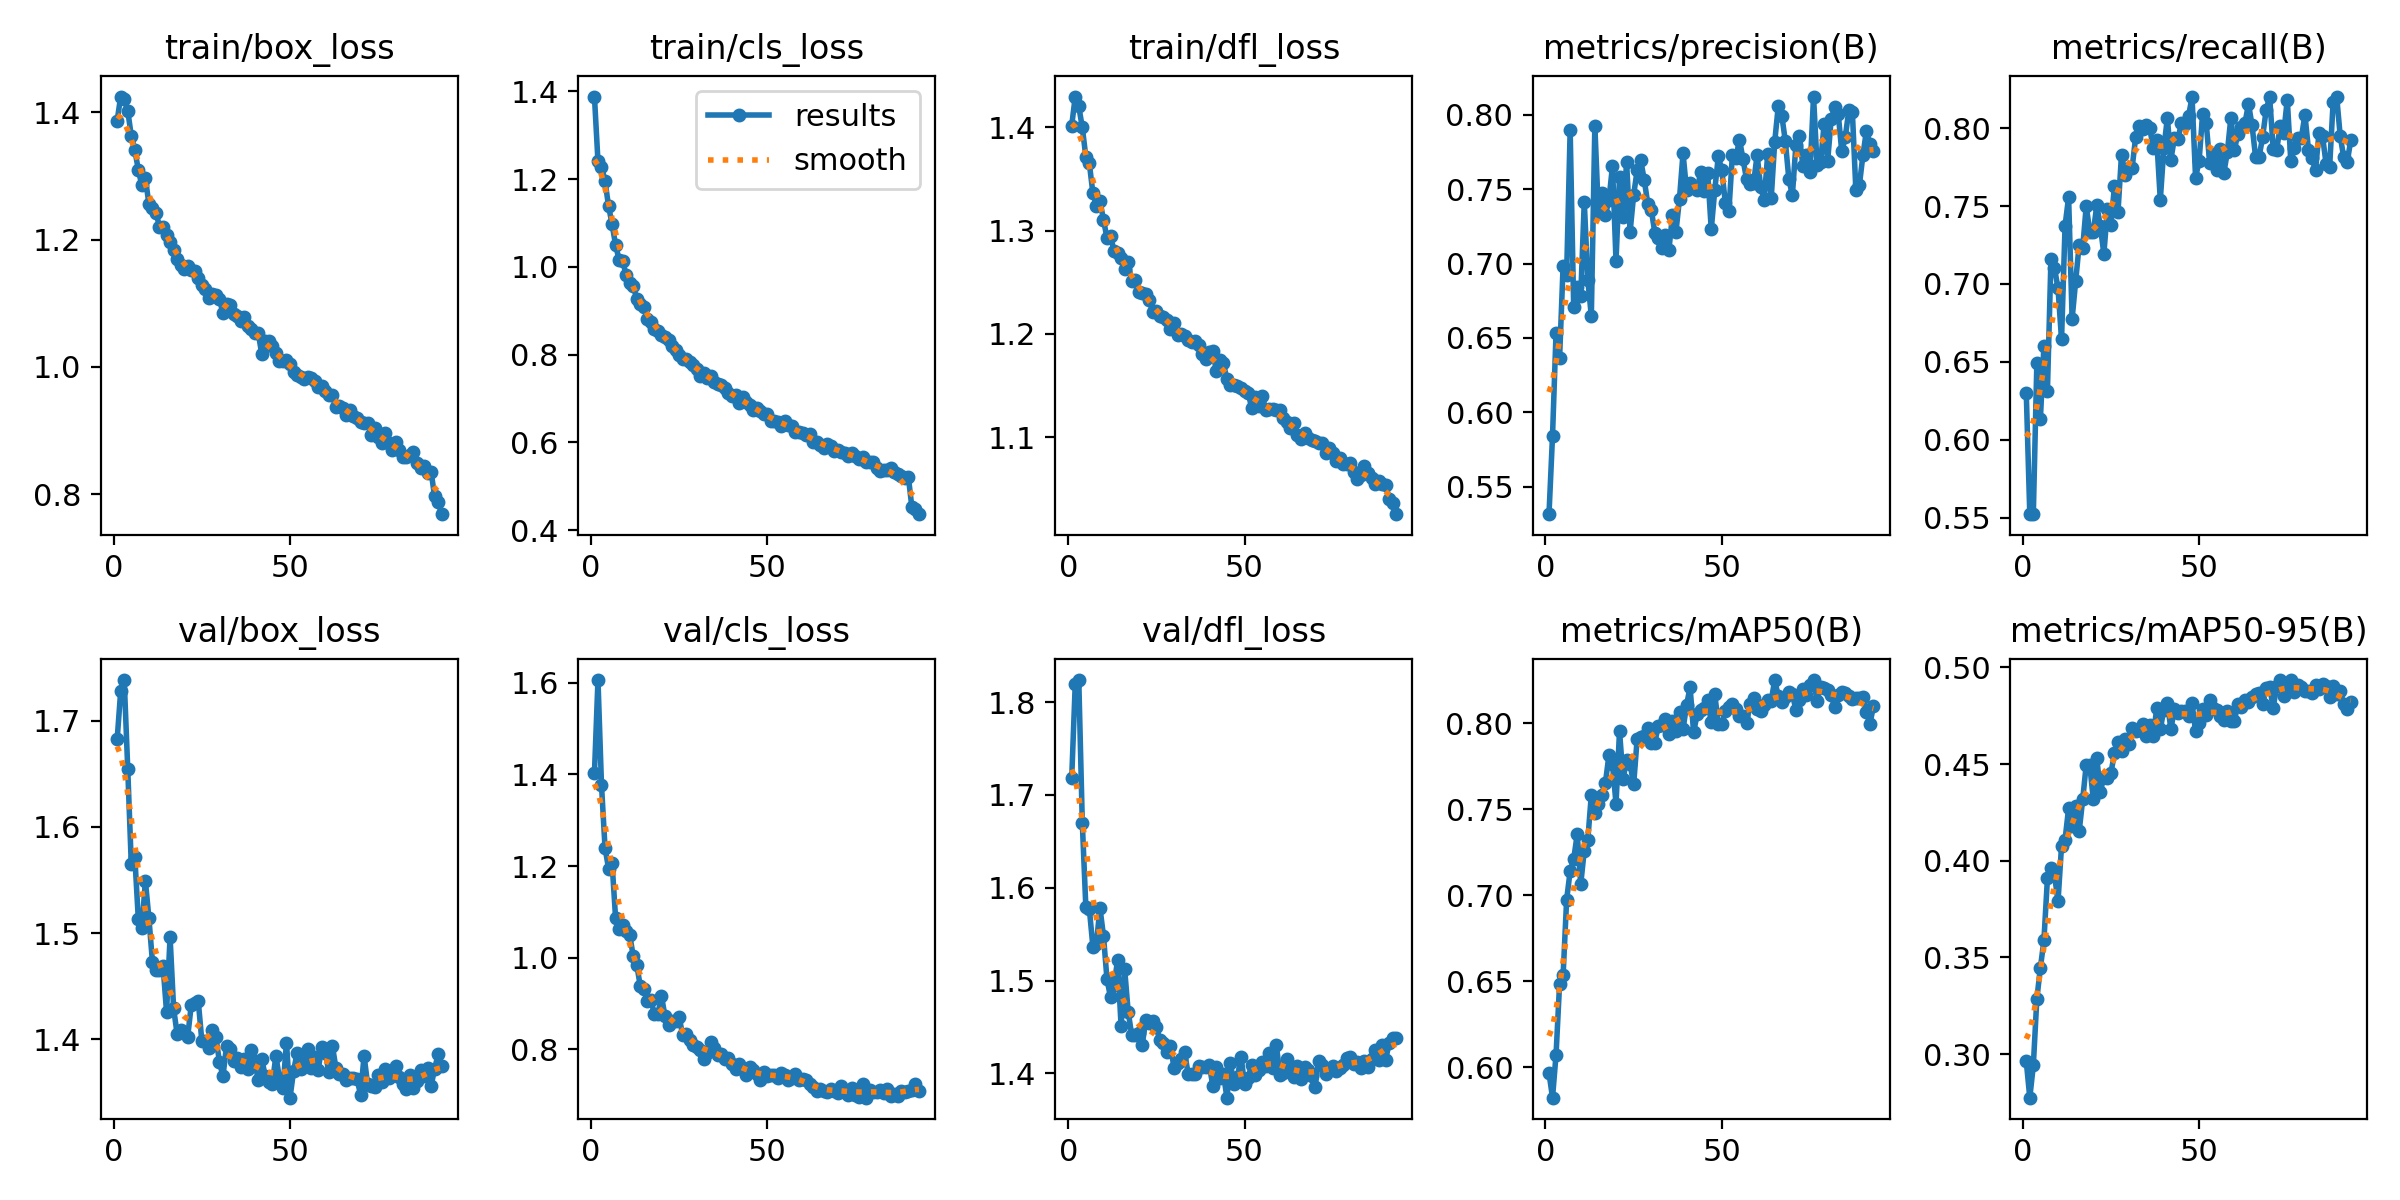

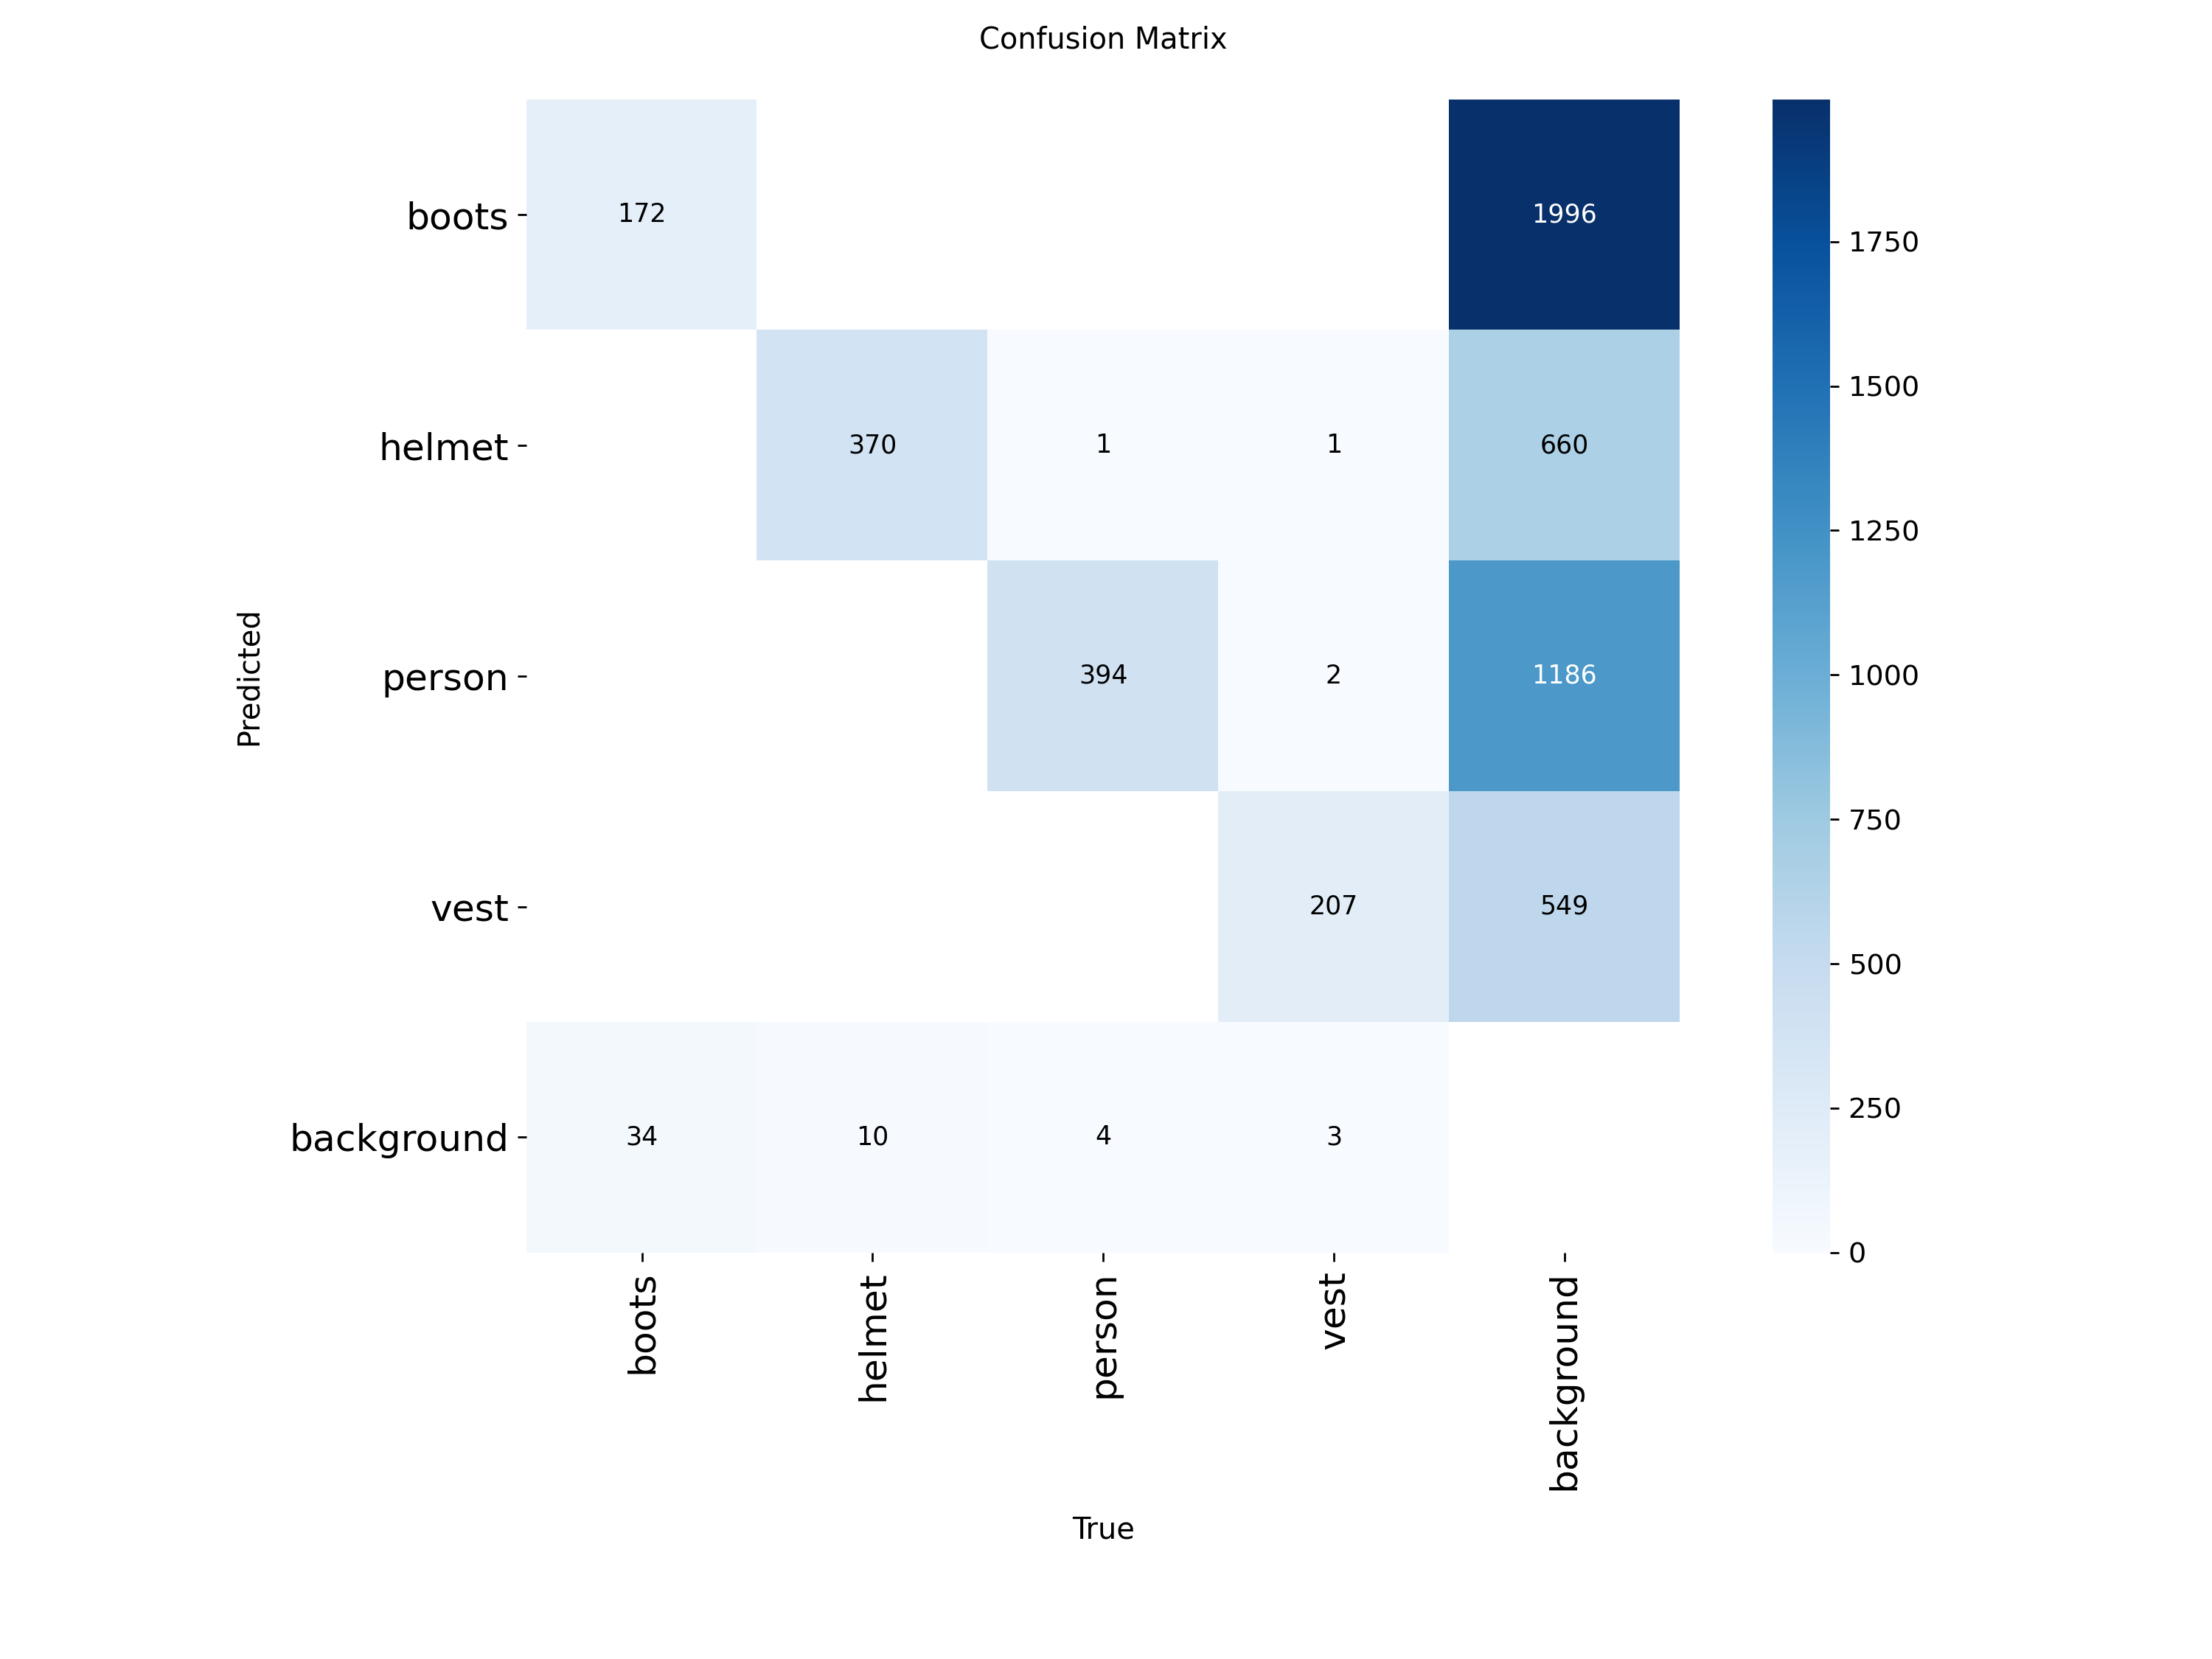

In [11]:
# ap50 chỉ chứa class được đánh giá; ap_class_index ánh xạ về class ID thật.
ap_by_class = {int(cid): float(ap) for cid, ap in zip(metrics.box.ap_class_index, metrics.box.ap50)}
per_class = pd.DataFrame([
    {'class_id': cid, 'class_name': name, 'mAP50': ap_by_class.get(cid, float('nan'))}
    for cid, name in sorted(class_names.items())
])
display(per_class)
print('NaN: class không có AP được đánh giá; không tự gán 0.')
validation_dir = Path(metrics.save_dir)
per_class.to_csv(validation_dir / 'per_class_map50.csv', index=False)
metrics_table = pd.DataFrame([{
    'Model': 'YOLO11s',
    'Params (M)': evaluation['params_millions'],
    'GFLOPs': evaluation['gflops'],
    'P': evaluation['precision'],
    'R': evaluation['recall'],
    'F1': evaluation['f1'],
    'mAP50': evaluation['mAP50'],
    'mAP50-95': evaluation['mAP50_95'],
    'Latency (ms/img)': evaluation['latency_inference_ms'],
}])
display(metrics_table.round(4))
metrics_table.to_csv(validation_dir / 'metrics_summary.csv', index=False)
summary = {
    **evaluation,
    'params_model_state': 'fused',
    'flops_input_shape': [1, 3, IMAGE_SIZE, IMAGE_SIZE],
    'f1_definition': 'Mean per-class F1 at the Ultralytics max-mean-F1 operating point (IoU 0.5)',
    'latency_method': 'Validation average per image; pipeline = preprocess + inference + postprocess; excludes file I/O',
    'latency_batch_size': BATCH_SIZE,
    'latency_precision': 'FP32',
    'device': str(DEVICE),
    'device_name': torch.cuda.get_device_name(DEVICE) if DEVICE != 'cpu' else 'CPU',
    'train_images': train_count, 'val_images': val_count,
    'model': 'yolo11s.pt', 'ultralytics': ultralytics.__version__,
    'torch': torch.__version__, 'epochs_requested': EPOCHS,
    'imgsz': IMAGE_SIZE, 'batch': BATCH_SIZE, 'seed': 42,
    'train_dir': str(run_dir), 'validation_dir': str(validation_dir),
    'created_utc': datetime.now(timezone.utc).isoformat()
}
with open(validation_dir / 'summary.json', 'w', encoding='utf-8') as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
for plot in (run_dir / 'results.png', validation_dir / 'confusion_matrix.png'):
    if plot.is_file():
        display(Image(filename=str(plot), width=900))


## 12. Predict ảnh validation


0: 640x640 1 person, 1 vest, 9.5ms
1: 640x640 1 helmet, 2 persons, 2 vests, 9.5ms
2: 640x640 1 person, 1 vest, 9.5ms
3: 640x640 1 person, 9.5ms
4: 640x640 1 helmet, 2 persons, 1 vest, 9.5ms
5: 640x640 1 helmet, 1 person, 9.5ms
6: 640x640 1 helmet, 1 person, 9.5ms
7: 640x640 1 helmet, 1 person, 9.5ms
8: 640x640 2 persons, 2 vests, 9.5ms
9: 640x640 1 boots, 1 person, 9.5ms
10: 640x640 1 helmet, 1 vest, 9.5ms
11: 640x640 1 person, 1 vest, 9.5ms
12: 640x640 1 person, 1 vest, 9.5ms
13: 640x640 1 vest, 9.5ms
14: 640x640 1 vest, 9.5ms
15: 640x640 1 vest, 9.5ms
16: 640x640 1 vest, 9.5ms
17: 640x640 1 helmet, 1 vest, 9.5ms
18: 640x640 1 person, 1 vest, 9.5ms
19: 640x640 1 vest, 9.5ms
20: 640x640 2 bootss, 1 helmet, 1 vest, 9.5ms
21: 640x640 2 bootss, 1 helmet, 1 vest, 9.5ms
22: 640x640 2 bootss, 1 helmet, 1 vest, 9.5ms
23: 640x640 2 bootss, 1 helmet, 1 vest, 9.5ms
24: 640x640 2 bootss, 1 helmet, 1 vest, 9.5ms
25: 640x640 2 bootss, 1 helmet, 1 vest, 9.5ms
26: 640x640 2 bootss, 1 helmet, 1 vest,

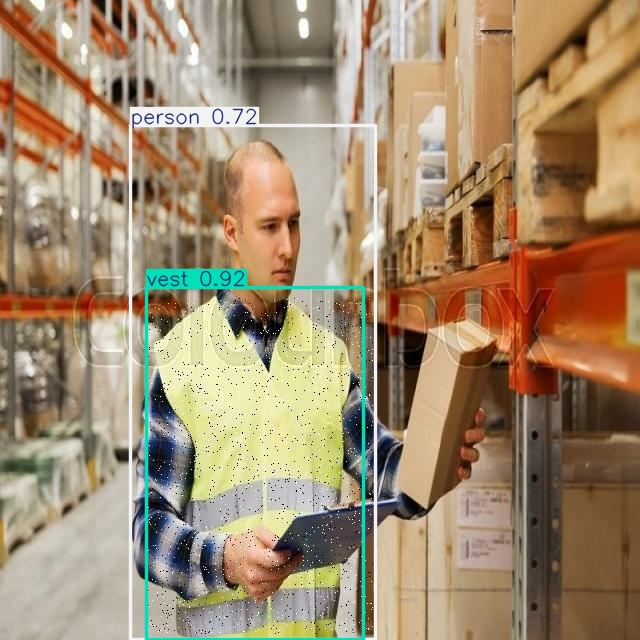

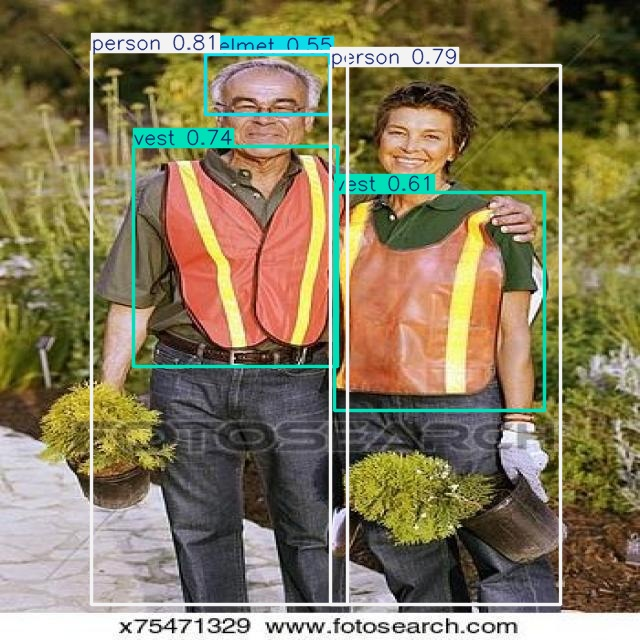

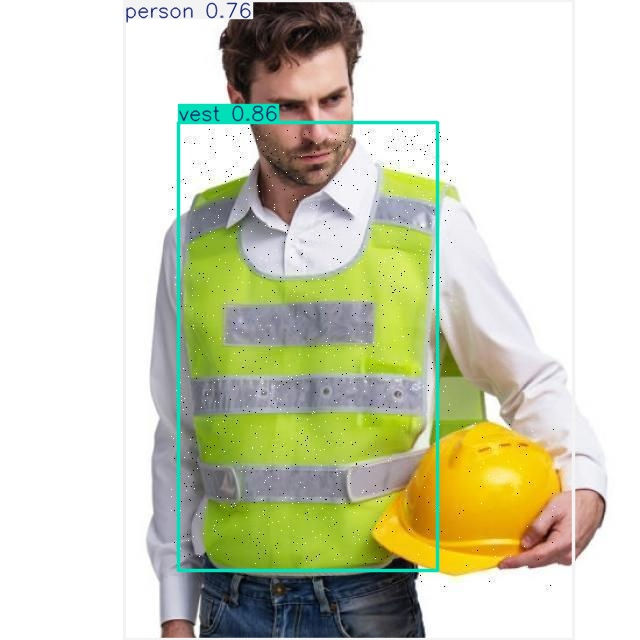

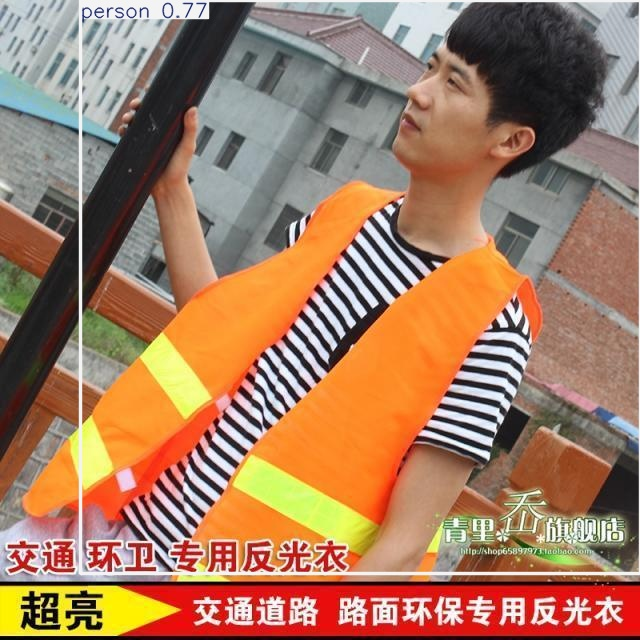

In [12]:
# stream=True: không giữ tất cả Results trong RAM; phải duyệt generator để chạy predict.
prediction_dir = None
prediction_count = 0
for prediction in best_model.predict(
    source=[str(p) for p in val_files],
    imgsz=IMAGE_SIZE, conf=0.5, device=DEVICE,
    save=True, stream=True,
    project='/kaggle/working/runs', name='ppe_yolo11s_predictions'
):
    prediction_dir = Path(prediction.save_dir)
    prediction_count += 1
assert prediction_count == val_count and prediction_dir is not None
print('Predicted images:', prediction_count)
print('Prediction outputs:', prediction_dir)
for preview in image_files(prediction_dir)[:4]:
    display(Image(filename=str(preview), width=700))


## 13. Output cần lưu

ZIP gồm thư mục train thực tế (best.pt, last.pt, results.csv, plots), validation (confusion matrix, summary.json, per_class_map50.csv), prediction và YAML đã chuẩn hóa.
Tên thư mục có thể được Ultralytics thêm hậu tố khi chạy lại; notebook dùng đường dẫn thực tế, không lấy nhầm checkpoint cũ.
Save Version trên Kaggle và giữ output để tải ZIP trong tab Output. FileLink cũng được cung cấp bên dưới.


In [13]:
import zipfile
zip_path = WORK_DIR / f'{run_dir.name}_results.zip'
with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for folder in (run_dir, validation_dir, prediction_dir):
        for file in sorted(folder.rglob('*')):
            if file.is_file():
                archive.write(file, arcname=str(Path(folder.name) / file.relative_to(folder)))
    archive.write(train_config_path, arcname='ppe_train.yaml')
    archive.writestr('environment.txt', subprocess.check_output(
        [sys.executable, '-m', 'pip', 'freeze'], text=True))
print(f'Đã nén: {zip_path} ({zip_path.stat().st_size / 1024**2:.2f} MB)')
display(FileLink(str(zip_path.relative_to(WORK_DIR))))


Đã nén: /kaggle/working/ppe_yolo11s_results.zip (72.33 MB)


/kaggle/working/ppe_yolo11s_results.zip